# CM laser: absolute keff and space-charge map from the CM data

**What changed w.r.t. `CM_laser_distortion_study.ipynb`**
1. **CM field**: every earlier laser fit ran at LaserClusterHelper's default 380 V/cm (no P/T correction). Now each beam block uses
   the P/T-corrected field PHGarfield computes from TPC_CONDITIONS (375.1-378.2 V/cm), references at 376.85 V/cm.
2. **Criterion**: keff was fitted on beam - no beam (space charge only). That leaves the static field-on curvature, which tracks
   do feel (DCA offsets of 2-6 mm). Now: the beam residual vs an **absolute** reference (CM truth, or field off) must have
   no constant R dphi term (= DCA of a TPC-only track) and no curvature (= sagitta, charge balance);
   a rotation (phi offset) and dR are allowed.
3. **keff tied to the GEM current with one coefficient for both sides**, so the North / South difference follows the currents.
4. **Map shape**: alpha 1.25 / 1.6 / 2.0 scanned together with the TPC z shift.

**Scan** (`make_absscan.py`, 625 jobs): 17 beam blocks (79508/13/16/29, 80892, 81558) x z {-50..0} x alpha {1.25, 1.6, 2.0}
x keff = a x I_R1 (a 0.36-0.60), tilt 0.16 / 0.85, survey x/y, IFC automatic; per-cluster residuals vs truth and field off.

**Result** (795xx, truth reference): alpha 2.0 (shape test 1.84 South / 1.9 North; DC density extraction 2.01 / 1.92),
z -40 (-30..-50 equivalent), keff = 0.81 x I_side with I_side = the all-module median GEM current of the side
(TPC_CONDITIONS SOUTH / NORTH) -> DCA +0.5 / +0.3 mm, sagitta -33 / -12 um; North / South follows the GEM currents.
High-luminosity runs (80892, 81558, ~6 uA) need b ~0.64 and a flatter profile: the luminosity dependence comes later.

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
import absplots as ap, cmplots as c
plt.rcParams['figure.dpi'] = 80
S = ap.data()
allfigs = {}
def show(figs, key):
    allfigs[key] = list(figs)
    for f in figs: display(f)
    plt.close('all')

## 1. Why the space-charge-only keff is not enough
For 79513 block 0 (alpha 1.6, z -30) the ring medians of R dphi vs truth for several keff, with the quadratic fit a TPC-only
track would absorb, extrapolated to R = 0. The space-charge-only keff (a ~0.41) leaves several mm at R = 0 and a positive sagitta.

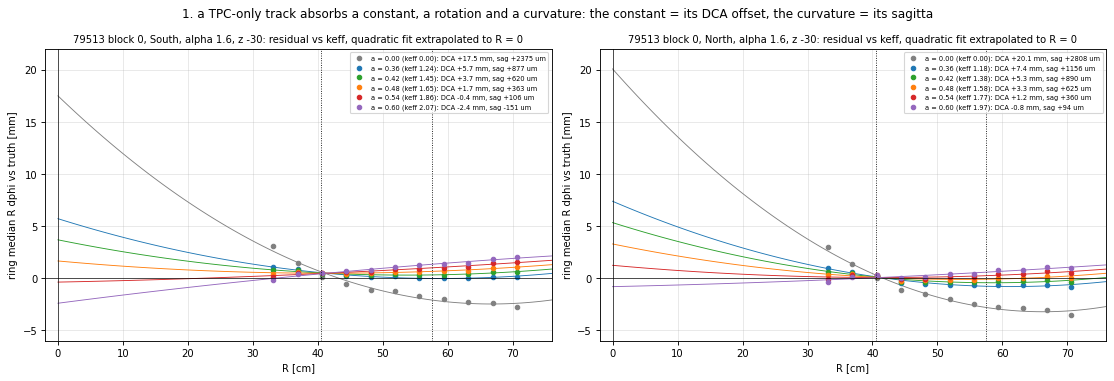

In [2]:
show(ap.sec_why(), 'why')

## 2. Map shape: alpha
With the right radial profile one keff zeroes both the DCA term and the sagitta; with the wrong one they need different keff.

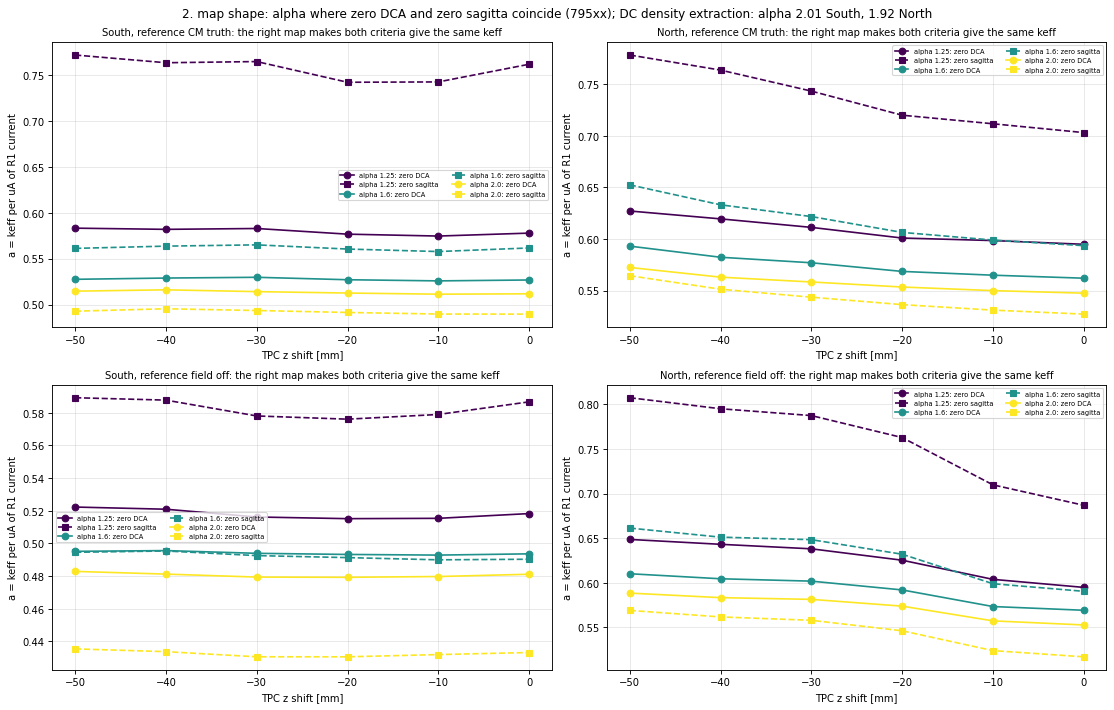

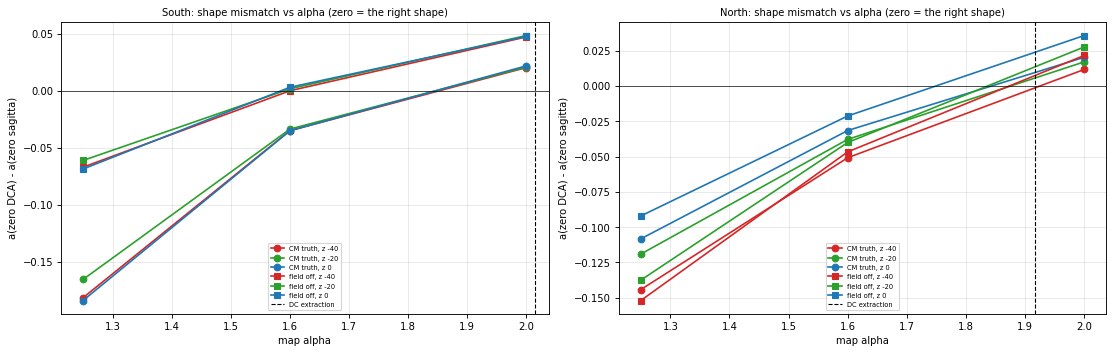

alpha where zero DCA and zero sagitta coincide (795xx):
  South vs field off z -40: alpha 1.60
  South vs field off z -20: alpha 1.59
  South vs field off z  +0: alpha 1.58
  South vs CM truth  z -40: alpha 1.85
  South vs CM truth  z -20: alpha 1.84
  South vs CM truth  z  +0: alpha 1.84
  North vs field off z -40: alpha 1.87
  North vs field off z -20: alpha 1.84
  North vs field off z  +0: alpha 1.75
  North vs CM truth  z -40: alpha 1.93
  North vs CM truth  z -20: alpha 1.88
  North vs CM truth  z  +0: alpha 1.84
DC primary-density extraction (stable v35 map): South 2.014, North 1.917


In [3]:
fa, est = ap.sec_alpha(); show(fa, 'alpha')
print("alpha where zero DCA and zero sagitta coincide (795xx):")
for k, v in sorted(est.items()): print(f"  {c.SIDES[k[0]]:5s} vs {ap.REFS[k[1]]:9s} z {k[2]:+3d}: alpha {v[0]:.2f}{v[1]}")
print(f"DC primary-density extraction (stable v35 map): South {ap.DC_ALPHA[0]}, North {ap.DC_ALPHA[1]}")

## 3. Which GEM current
With the R1 currents North needs ~10 % more keff per uA than South. That is exactly the ratio between the all-module
and the R1 current ratios: with the all-module side currents (TPC_CONDITIONS SOUTH / NORTH medians) North and South take
the same coefficient.

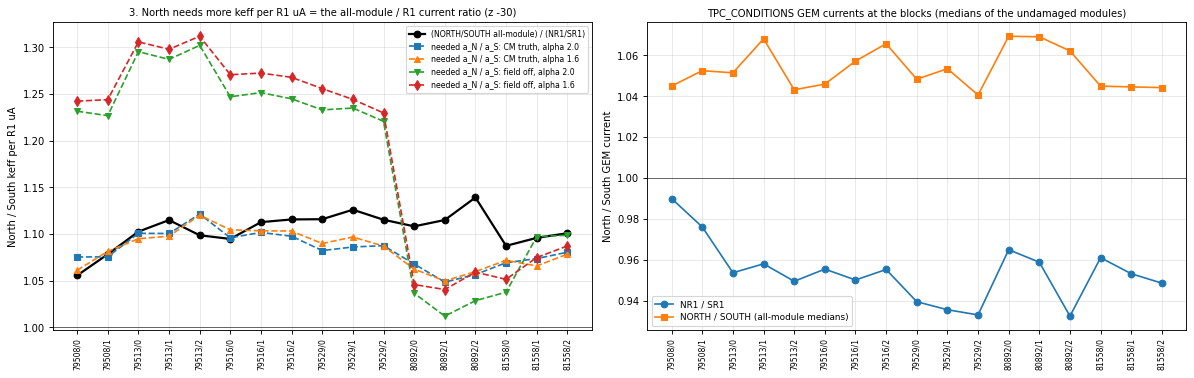

In [4]:
fc, rows = ap.sec_current(); show(fc, 'current')

## 4. Joint minimization: alpha, z and one coefficient b (keff = b x I_side) for both sides
chi2 = sum over the 11 blocks of the 795xx runs and both sides of (DCA / 1 mm)^2 + (sagitta / 100 um)^2, reference CM truth.

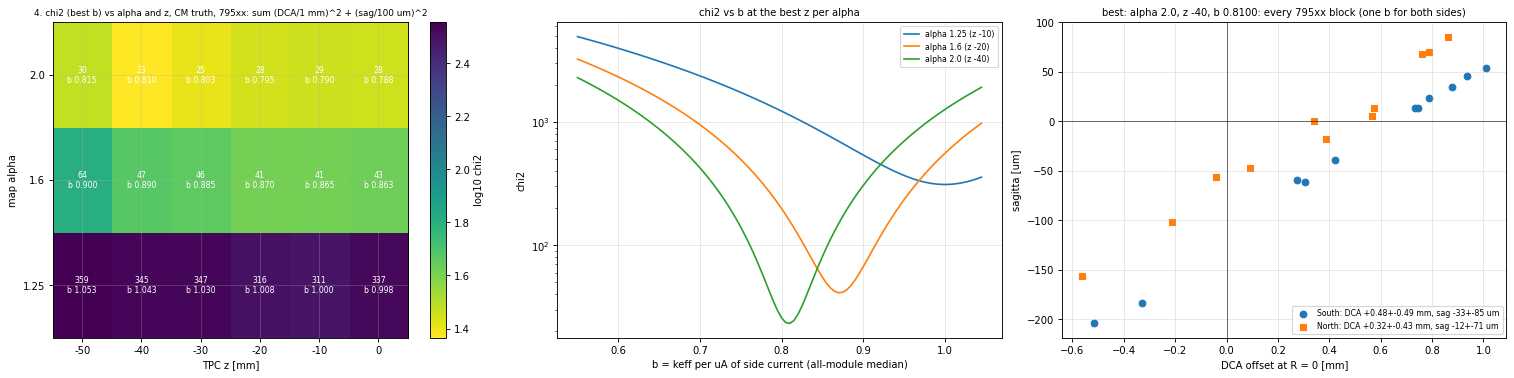

best (truth reference, keff = b x I_side all-module):
  chi2   23.2  alpha 2.0  z -40  b 0.8100
  chi2   25.3  alpha 2.0  z -30  b 0.8025
  chi2   28.0  alpha 2.0  z -20  b 0.7950
  chi2   28.3  alpha 2.0  z +0  b 0.7875
  chi2   28.6  alpha 2.0  z -10  b 0.7900
with R1 currents instead: best chi2 68.6 (alpha 2.0, z 0, a 0.5125) - much worse
field off as reference: best [(39.3, 1.6, 0, 0.8225), (55.0, 1.6, -10, 0.8275), (65.5, 2.0, 0, 0.7475)]


In [5]:
ff, res, resR1 = ap.sec_fit(1); show(ff, 'fit')
print("best (truth reference, keff = b x I_side all-module):")
for r in res[:5]: print(f"  chi2 {r[0]:6.1f}  alpha {r[1]}  z {r[2]:+d}  b {r[3]:.4f}")
print(f"with R1 currents instead: best chi2 {resR1[0][0]:.1f} (alpha {resR1[0][1]}, z {resR1[0][2]}, a {resR1[0][3]:.4f}) - much worse")
fo, reso, _ = ap.sec_fit(0); allfigs['fit_fieldoff'] = fo; plt.close('all')
print("field off as reference: best", [(round(r[0], 1), r[1], r[2], round(r[3], 4)) for r in reso[:3]])

## 5. Per run: b and the luminosity

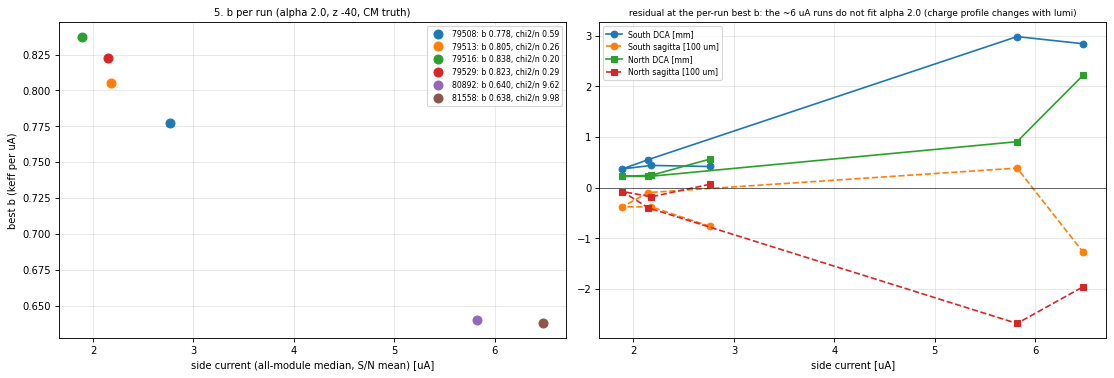

  79508: b 0.7775  I_S 2.70 I_N 2.83 uA  chi2/n 0.59
  79513: b 0.8050  I_S 2.12 I_N 2.24 uA  chi2/n 0.26
  79516: b 0.8375  I_S 1.84 I_N 1.94 uA  chi2/n 0.20
  79529: b 0.8225  I_S 2.10 I_N 2.20 uA  chi2/n 0.29
  80892: b 0.6400  I_S 5.63 I_N 6.01 uA  chi2/n 9.62
  81558: b 0.6375  I_S 6.34 I_N 6.62 uA  chi2/n 9.98


In [6]:
fr, rr = ap.sec_runs(); show(fr, 'runs')
for r in rr: print(f"  {r[0]}: b {r[1]:.4f}  I_S {r[2]:.2f} I_N {r[3]:.2f} uA  chi2/n {r[4]:.2f}")

## 6. Residual biases at the best point
Ring profiles per run (vs truth and vs field off), sagitta per 30 deg sector, dR per ring and all clusters (795xx).

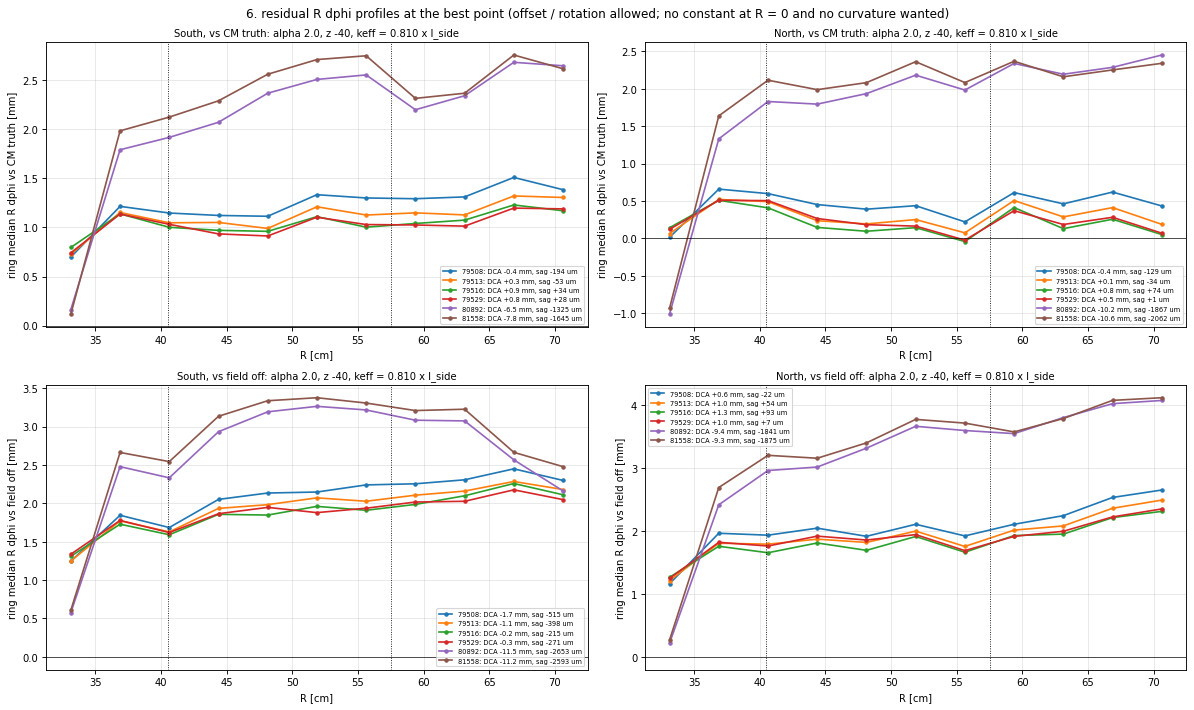

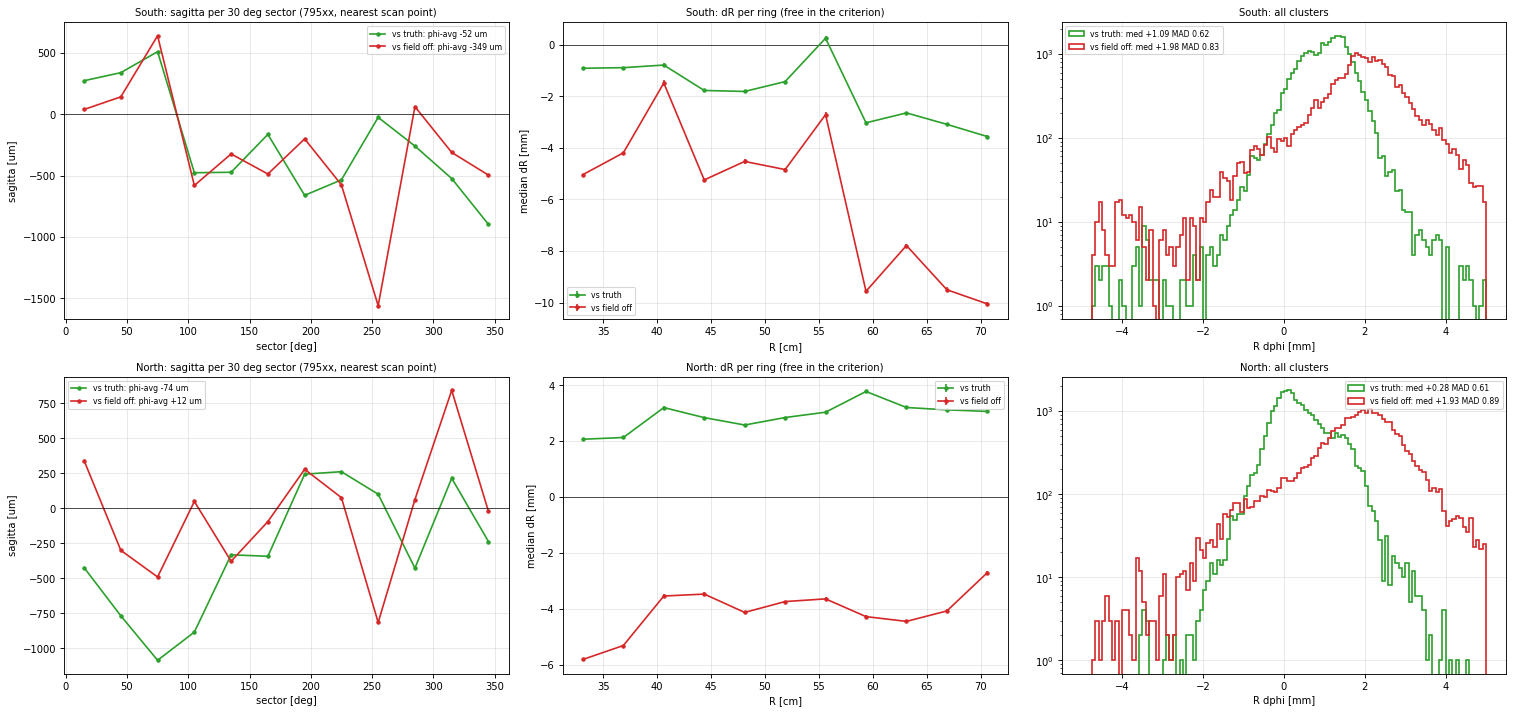

In [7]:
show(ap.sec_bias(), 'bias')

## 7. keff per block and the settings for the tracking test

In [8]:
b, rows = ap.keff_table()
print(f"keff = {b:.4f} x I_side (all-module median GEM current of the side, TPC_CONDITIONS SOUTH / NORTH), alpha 2.0 map, z -40 mm")
print(f"{'run':>6s} {'block':>6s} {'I_SOUTH':>8s} {'I_NORTH':>8s} {'keff S':>7s} {'keff N':>7s} {'x CDB S':>8s} {'x CDB N':>8s}")
for r in rows: print(f"{r[0]:6d} {r[1]:6d} {r[2]:8.3f} {r[3]:8.3f} {r[4]:7.3f} {r[5]:7.3f} {r[6]:8.3f} {r[7]:8.3f}" + ("   * high lumi: NOT valid (needs b ~0.64 and a flatter profile, section 5)" if r[0] not in c.LOWLUMI else ""))
k0 = [r for r in rows if r[0] == 79513 and r[1] == 0][0]
print(f'''
79513 segment 0 (block 0):
  garfield->MoveTpc(-0.16775, -0.0336, -4.0);   // z -40 mm
  garfield->RotateTpc(0.16e-3, 0.85e-3, 0.);
  garfield->SetElectricFieldMap3D(".../sphenix_3d_ibf_field_side0_South_v35Lalpha2p0.root", ".../sphenix_3d_ibf_field_side1_North_v35Lalpha2p0.root");
  garfield->SetSpaceChargeScaleSide0({k0[4]:.3f});
  garfield->SetSpaceChargeScaleSide1({k0[5]:.3f});''')

keff = 0.8100 x I_side (all-module median GEM current of the side, TPC_CONDITIONS SOUTH / NORTH), alpha 2.0 map, z -40 mm
   run  block  I_SOUTH  I_NORTH  keff S  keff N  x CDB S  x CDB N
 79508      0    2.744    2.867   2.222   2.322    1.155    1.194
 79508   1000    2.649    2.788   2.146   2.258    1.115    1.161
 79513      0    2.149    2.260   1.741   1.831    1.123    1.181
 79513   1000    2.113    2.257   1.712   1.828    1.104    1.179
 79513   2000    2.101    2.192   1.702   1.776    1.098    1.145
 79516      0    1.866    1.951   1.511   1.581    1.087    1.142
 79516   1000    1.837    1.942   1.488   1.573    1.070    1.136
 79516   2000    1.810    1.929   1.466   1.562    1.055    1.128
 79529      0    2.134    2.237   1.729   1.812    1.108    1.177
 79529   1000    2.090    2.202   1.693   1.784    1.085    1.159
 79529   2000    2.071    2.155   1.678   1.746    1.075    1.134
 80892      0    5.908    6.317   4.785   5.117    1.222    1.304   * high lumi: NOT v

### Summary
| | value | from |
|---|---|---|
| CM field | P/T corrected (TpcConditions), not 380 V/cm | |
| map | alpha 2.0 (shape test 1.84 S / 1.9 N vs truth; DC extraction 2.01 / 1.92) | 2 |
| GEM current for keff | all-module side median (SOUTH / NORTH), not R1 | 3 |
| keff | 0.81 x I_side (795xx; slightly sub-linear: 0.78-0.84 per run) | 4, 5 |
| TPC z | -40 mm (-30..-50 within chi2 +10 %) | 4 |
| tilt | 0.16 / 0.85 mrad | earlier |
| residual (795xx, vs truth) | DCA +0.5 / +0.3 mm, sagitta -33 / -12 um (S / N) | 4, 6 |

Open: the high-luminosity runs (80892, 81558: b ~0.64, flatter profile) - the radial profile changes with luminosity;
maps beyond alpha 2.0 and finer alpha; the field-off reference prefers alpha 1.6 South.

In [9]:
import os
os.makedirs('pdf', exist_ok=True)
from matplotlib.backends.backend_pdf import PdfPages
with PdfPages('pdf/absolute_keff.pdf') as pdf:
    for k, figs in allfigs.items():
        for f in figs: pdf.savefig(f)
print("wrote pdf/absolute_keff.pdf")

wrote pdf/absolute_keff.pdf
